In [1]:
!pip install networkx


In [2]:
import networkx as nx
import matplotlib.pyplot as plt

1. Graph Types in NetworkX

NetworkX provides several graph types:

    Graph → Undirected graph (single edge between nodes)
    DiGraph → Directed graph (single directed edge)
    MultiGraph → Undirected graph that allows multiple parallel edge.
    MultiDiGraph → Directed graph that allows multiple directed parallel edges

In [15]:
# Undirected Graph
G = nx.Graph()

# Directed Graph
DG = nx.DiGraph()

# Multigraph
MG = nx.MultiGraph()

# Directed Multigraph
DMG = nx.MultiDiGraph()

-> Adding Nodes and Edges

In [16]:
G = nx.Graph()

# Add nodes
G.add_node(1)
G.add_nodes_from([2, 3, 4])

# Add edges
G.add_edge(1, 2)
G.add_edges_from([(2, 3), (3, 4)])

print("Nodes:", G.nodes())
print("Edges:", G.edges())

Nodes: [1, 2, 3, 4]
Edges: [(1, 2), (2, 3), (3, 4)]


-> Adding Attributes

In [18]:
# Node attributes
names = {1: 'Alice', 2: 'Bob', 3: 'Charlie', 4: 'Diana'}
for node, name in names.items():
    G.nodes[node]['name'] = name

# Edge attributes
weights = {(1, 2): 4.5, (2, 3): 5, (3, 4): 6.2}
for edge, weight in weights.items():
    G.edges[edge]['weight'] = weight

print(G.nodes(data=True))
print(G.edges(data=True))

[(1, {'name': 'Alice'}), (2, {'name': 'Bob'}), (3, {'name': 'Charlie'}), (4, {'name': 'Diana'})]
[(1, 2, {'weight': 4.5}), (2, 3, {'weight': 5}), (3, 4, {'weight': 6.2})]


-> Graph Visualization

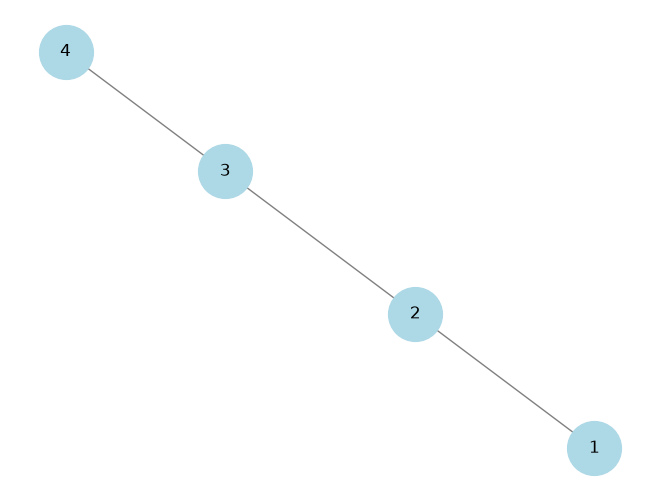

In [19]:
# Simple Visualization with Edges and Nodes
nx.draw(G, with_labels=True, node_color='lightblue', edge_color='gray', node_size=1500)
plt.show()

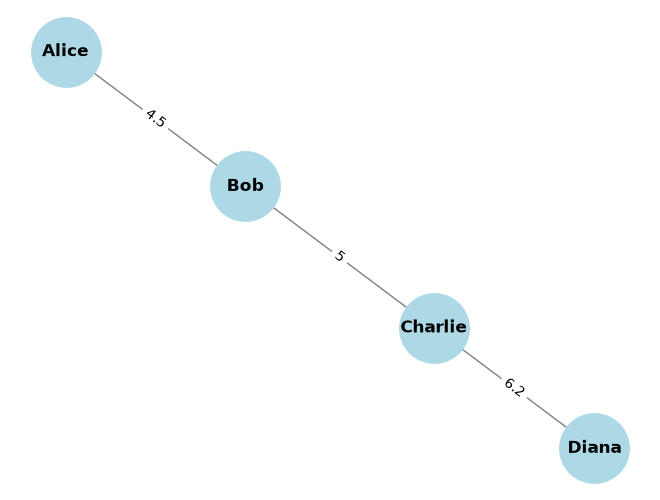

In [20]:
# Visualization with Attributes
pos = nx.spring_layout(G) 
nx.draw(G, pos, node_color='lightblue', edge_color='gray', node_size=2500, with_labels=False)

node_labels = {node: G.nodes[node].get('name', node) for node in G.nodes()}
nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=12, font_weight='bold')

edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.show()

In [21]:
# Directed Graph
DG = nx.DiGraph()
DG.add_edges_from([(1, 2), (2, 3), (3, 1)])

print("Nodes:", DG.nodes())
print("Edges:", DG.edges())

# In-degree and out-degree
print("In-degree:", DG.in_degree())
print("Out-degree:", DG.out_degree())

Nodes: [1, 2, 3]
Edges: [(1, 2), (2, 3), (3, 1)]
In-degree: [(1, 1), (2, 1), (3, 1)]
Out-degree: [(1, 1), (2, 1), (3, 1)]


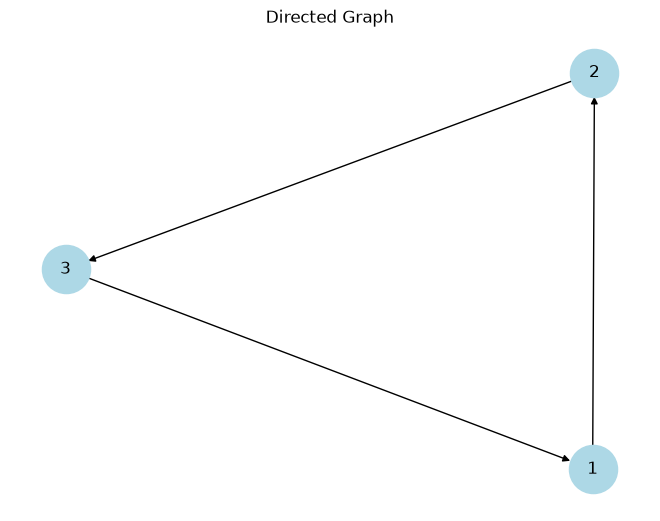

In [22]:
import matplotlib.pyplot as plt

nx.draw(DG, with_labels=True, node_color='lightblue', arrows=True, node_size=1200)
plt.title("Directed Graph")
plt.show()

-> Undirected Multigraph

In [23]:
MG = nx.MultiGraph()
MG.add_edges_from([(1, 2), (2, 3), (3, 1), (1, 2)])  

print("MultiGraph Nodes:", MG.nodes())
print("MultiGraph Edges:", MG.edges())
print("MultiGraph Edge Count:", MG.number_of_edges())

MultiGraph Nodes: [1, 2, 3]
MultiGraph Edges: [(1, 2), (1, 2), (1, 3), (2, 3)]
MultiGraph Edge Count: 4


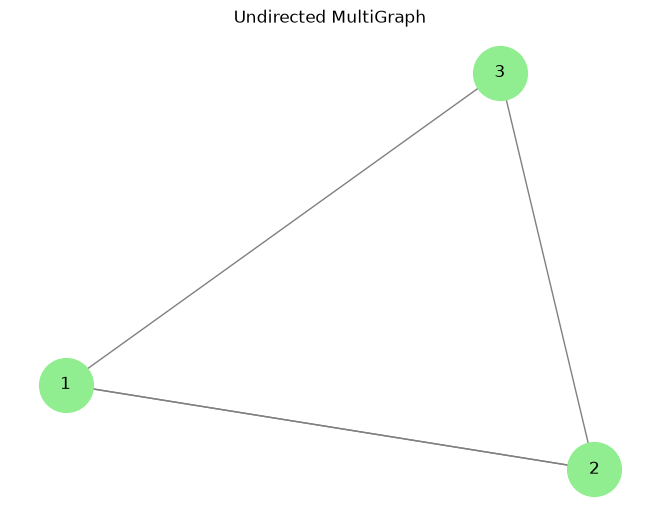

In [24]:
pos = nx.spring_layout(MG)
nx.draw(MG, pos, with_labels=True, node_color='lightgreen', edge_color='gray', node_size=1500)
plt.title("Undirected MultiGraph")
plt.show()

In [25]:

DMG = nx.MultiDiGraph()
DMG.add_edges_from([(1, 2), (2, 3), (3, 1), (1, 2)])

print("MultiDiGraph Nodes:", DMG.nodes())
print("MultiDiGraph Edges:", DMG.edges())
print("MultiDiGraph Edge Count:", DMG.number_of_edges())

MultiDiGraph Nodes: [1, 2, 3]
MultiDiGraph Edges: [(1, 2), (1, 2), (2, 3), (3, 1)]
MultiDiGraph Edge Count: 4


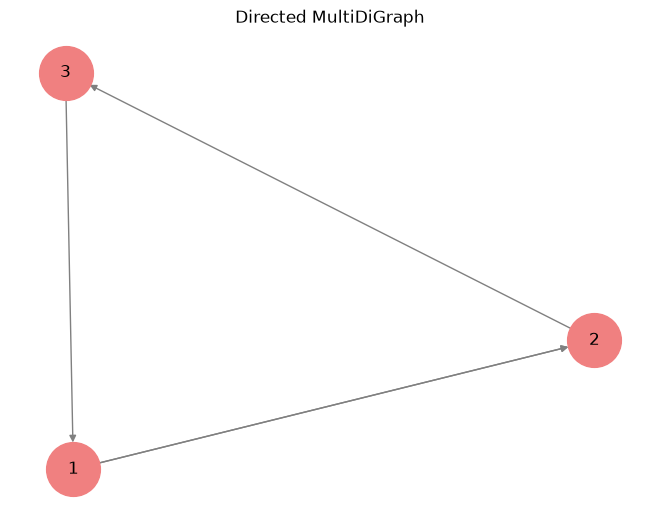

In [26]:
pos = nx.spring_layout(DMG)
nx.draw(DMG, pos, with_labels=True, node_color='lightcoral', edge_color='gray', node_size=1500, arrows=True)
plt.title("Directed MultiDiGraph")
plt.show()

-> Traversals


In [27]:
# DFS
G = nx.Graph()
G.add_edges_from([(1,2),(1,3),(2,4),(2,5),(5,3),(5,6),(6,7)])

# DFS edges starting from node 1
dfs_edges = list(nx.dfs_edges(G, source=1))
print("DFS Edges:", dfs_edges)

# DFS Traversal Order (Nodes)
dfs_nodes = list(nx.dfs_preorder_nodes(G, source=1))
print("DFS Node Order:", dfs_nodes)

DFS Edges: [(1, 2), (2, 4), (2, 5), (5, 3), (5, 6), (6, 7)]
DFS Node Order: [1, 2, 4, 5, 3, 6, 7]


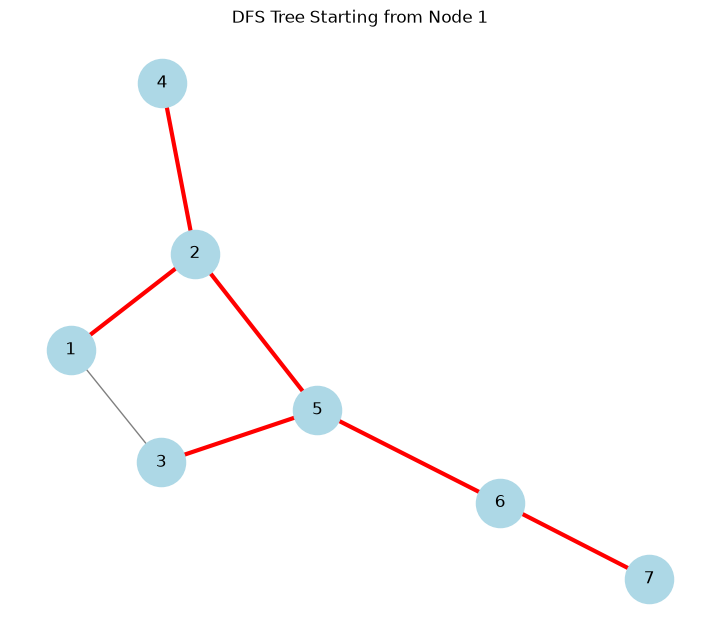

In [28]:

dfs_tree = nx.dfs_tree(G, source=1)
dfs_edges = list(dfs_tree.edges())

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(7,6))

# Draw the full graph
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray", node_size=1200)

# Highlight DFS edges
nx.draw_networkx_edges(G, pos, edgelist=dfs_edges, edge_color="red", width=3)

plt.title("DFS Tree Starting from Node 1")
plt.show()

In [29]:
# BFS
G = nx.Graph()
G.add_edges_from([(1,2),(1,3),(2,4),(2,5),(5,3),(5,6),(6,7)])

# BFS edges starting from node 1
bfs_edges = list(nx.bfs_edges(G, source=1))
print("BFS Edges:", bfs_edges)

# BFS Traversal Order (Nodes)
bfs_nodes = list(nx.bfs_tree(G, source=1))
print("BFS Node Order:", bfs_nodes)

BFS Edges: [(1, 2), (1, 3), (2, 4), (2, 5), (5, 6), (6, 7)]
BFS Node Order: [1, 2, 3, 4, 5, 6, 7]


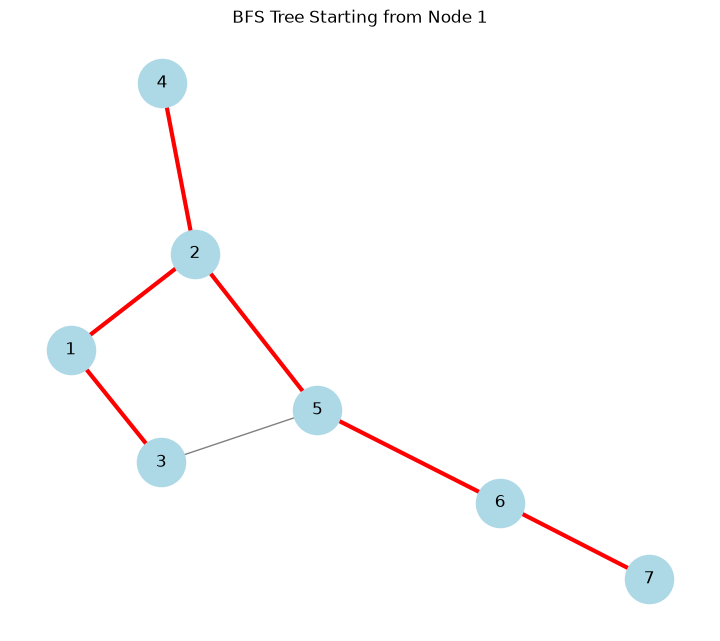

In [30]:
bfs_tree = nx.bfs_tree(G, source=1)
bfs_edges = list(bfs_tree.edges())

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(7,6))

# Draw the full graph
nx.draw(G, pos, with_labels=True, node_color="lightblue", edge_color="gray", node_size=1200)

# Highlight BFS edges
nx.draw_networkx_edges(G, pos, edgelist=bfs_edges, edge_color="red", width=3)

plt.title("BFS Tree Starting from Node 1")
plt.show()

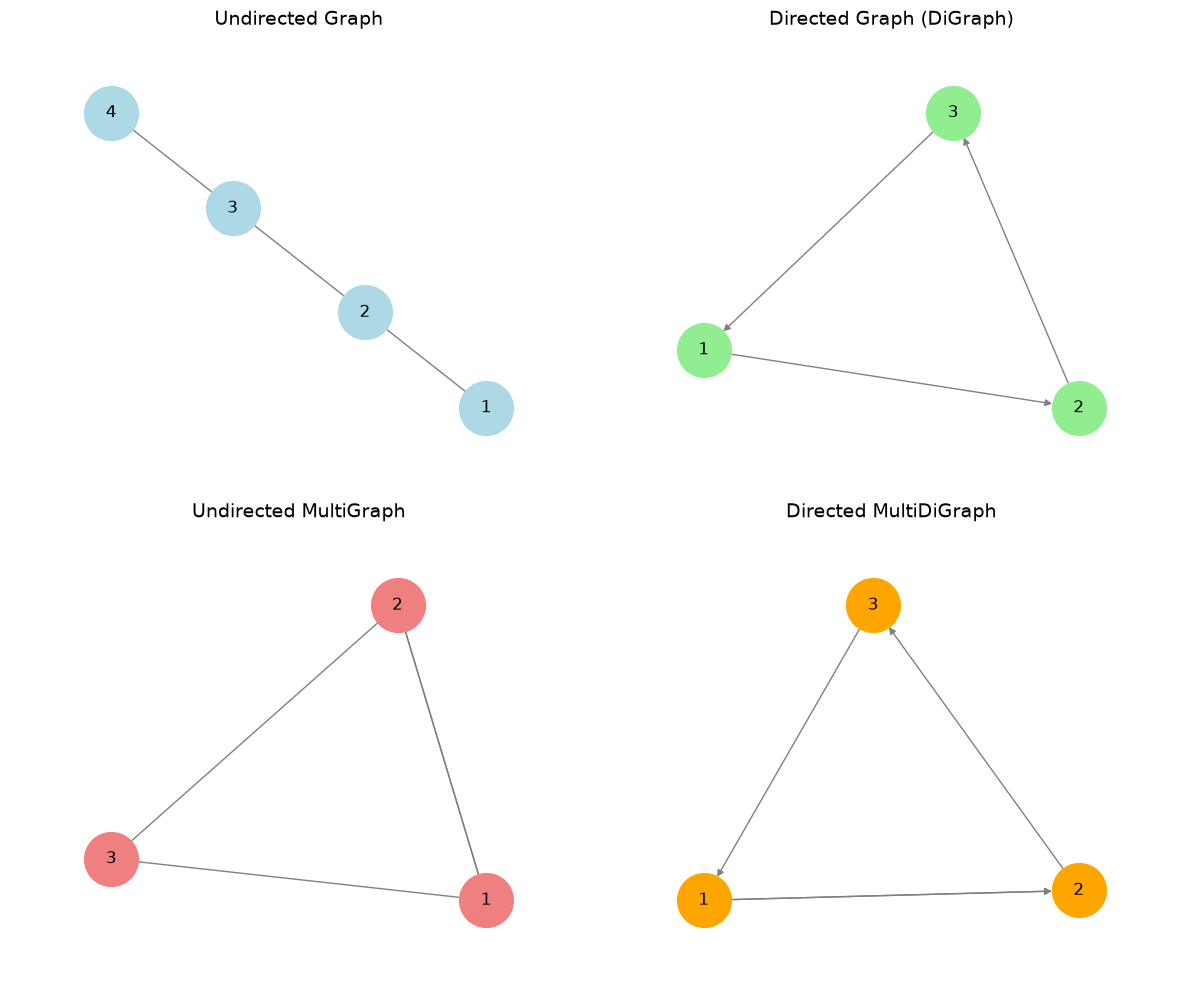

In [31]:
# 1. Undirected Graph
G = nx.Graph()
G.add_edges_from([(1, 2), (2, 3), (3, 4)])

# 2. Directed Graph
DG = nx.DiGraph()
DG.add_edges_from([(1, 2), (2, 3), (3, 1)])

# 3. Undirected MultiGraph
MG = nx.MultiGraph()
MG.add_edges_from([(1, 2), (2, 3), (3, 1), (1, 2)])

# 4. Directed MultiDiGraph
DMG = nx.MultiDiGraph()
DMG.add_edges_from([(1, 2), (2, 3), (3, 1), (1, 2)])

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

posG   = nx.spring_layout(G, seed=10)
posDG  = nx.spring_layout(DG, seed=10)
posMG  = nx.spring_layout(MG, seed=10)
posDMG = nx.spring_layout(DMG, seed=10)

def draw_graph(ax, graph, pos, title, color, directed=False):
    nx.draw(graph, pos, with_labels=True, node_color=color, node_size=1500, edge_color='gray', arrows=directed, clip_on=False, ax=ax)
    ax.set_title(title, fontsize=14)
    ax.margins(0.2)        
    ax.set_axis_off()

draw_graph(axes[0,0], G, posG,   "Undirected Graph",          "lightblue")
draw_graph(axes[0,1], DG, posDG, "Directed Graph (DiGraph)",  "lightgreen", directed=True)
draw_graph(axes[1,0], MG, posMG, "Undirected MultiGraph",     "lightcoral")
draw_graph(axes[1,1], DMG, posDMG,"Directed MultiDiGraph",    "orange", directed=True)

plt.tight_layout()
plt.show()

## Built-in datasets


The Karate Club Graph represents a friendship network of 34 members of a university karate club.

    Classic dataset in network science
    Used heavily for community detection

Number of nodes: 34
Number of edges: 78


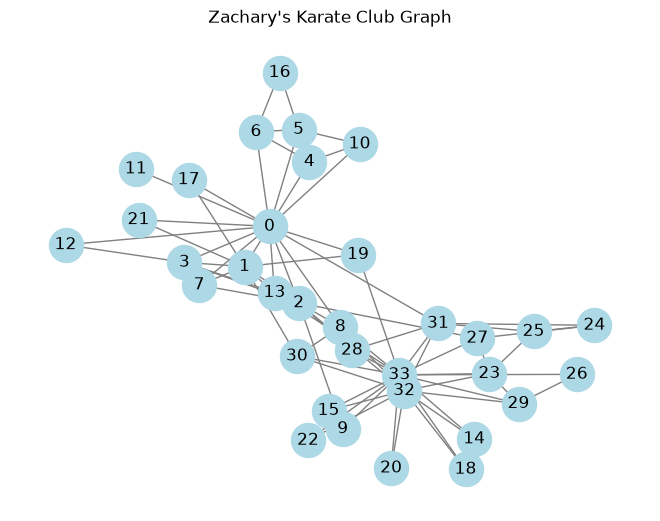

In [32]:

G = nx.karate_club_graph()

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

pos = nx.spring_layout(G, seed=42)

nx.draw(G, pos, with_labels=True, node_color="lightblue", node_size=600, edge_color="gray")

plt.title("Zachary's Karate Club Graph")
plt.show()

Florentine Families Graph

This dataset represents marriage relationships among influential families in Renaissance Florence.

    Demonstrates power and influence
    Great for centrality analysis
    Frequently used in sociology

['Acciaiuoli', 'Medici', 'Castellani', 'Peruzzi', 'Strozzi', 'Barbadori', 'Ridolfi', 'Tornabuoni', 'Albizzi', 'Salviati', 'Pazzi', 'Bischeri', 'Guadagni', 'Ginori', 'Lamberteschi']
[('Acciaiuoli', 'Medici'), ('Medici', 'Barbadori'), ('Medici', 'Ridolfi'), ('Medici', 'Tornabuoni'), ('Medici', 'Albizzi'), ('Medici', 'Salviati'), ('Castellani', 'Peruzzi'), ('Castellani', 'Strozzi'), ('Castellani', 'Barbadori'), ('Peruzzi', 'Strozzi'), ('Peruzzi', 'Bischeri'), ('Strozzi', 'Ridolfi'), ('Strozzi', 'Bischeri'), ('Ridolfi', 'Tornabuoni'), ('Tornabuoni', 'Guadagni'), ('Albizzi', 'Ginori'), ('Albizzi', 'Guadagni'), ('Salviati', 'Pazzi'), ('Bischeri', 'Guadagni'), ('Guadagni', 'Lamberteschi')]


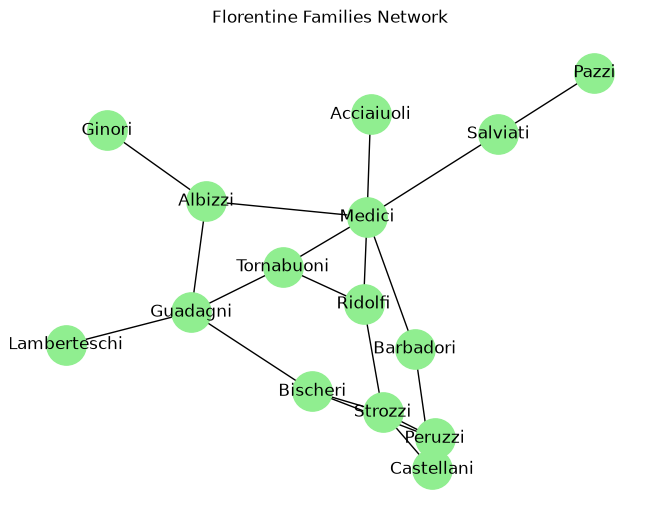

In [33]:
G = nx.florentine_families_graph()

print(G.nodes())
print(G.edges())

nx.draw(G, with_labels=True, node_color="lightgreen", node_size=800)

plt.title("Florentine Families Network")
plt.show()

Davis Southern Women Graph

This dataset models women attending social events, forming a bipartite graph.

    Shows bipartite graph structure
    Useful for projections
    Common in social network analysis

Number of nodes: 32
Number of edges: 89


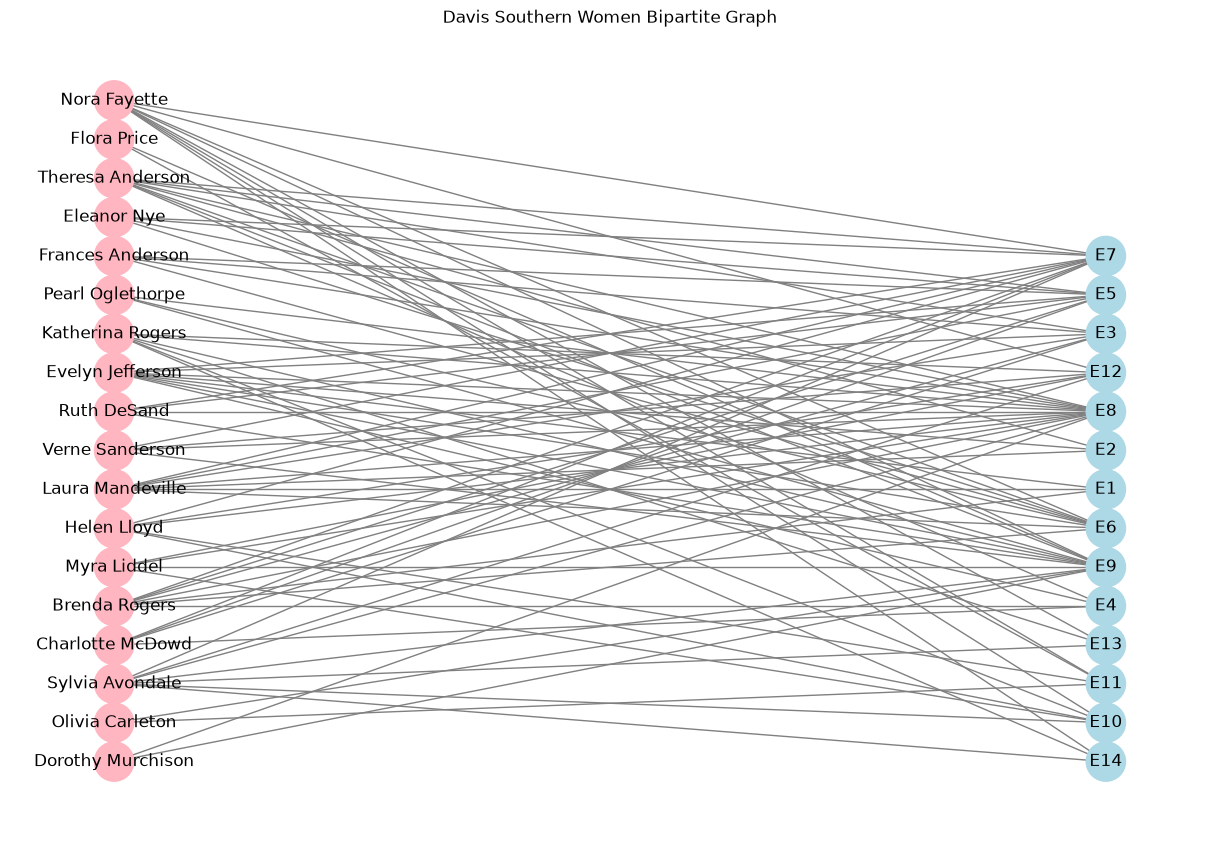

In [34]:
G = nx.davis_southern_women_graph()

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

women = {n for n, d in G.nodes(data=True) if d["bipartite"] == 0}
events = set(G) - women

pos = {}
pos.update((n, (0, i)) for i, n in enumerate(women))
pos.update((n, (1, i)) for i, n in enumerate(events))

plt.figure(figsize=(12, 8))

nx.draw(G, pos, with_labels=True, node_size=800,
    node_color=["lightpink" if n in women else "lightblue" for n in G],
    edge_color="gray"
)

plt.title("Davis Southern Women Bipartite Graph")
plt.axis("off")
plt.show()

Les Misérables Character Network

This dataset represents co-occurrence of characters in Les Misérables.

    Weighted edges
    Natural community structure
    Perfect for centrality & clustering

Nodes: 77
Edges: 254


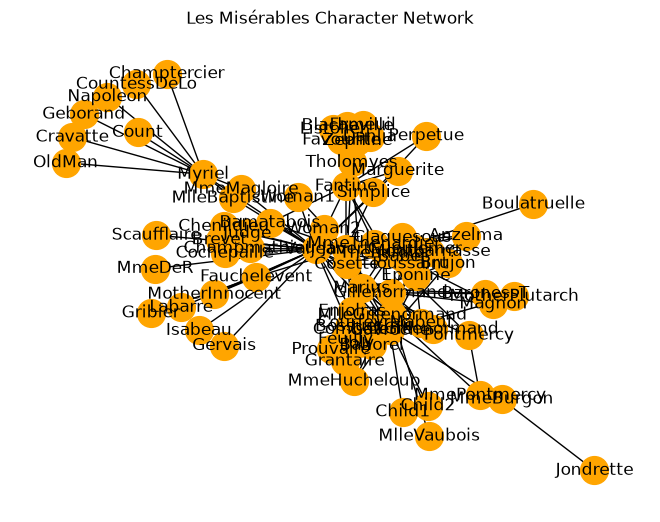

In [35]:
G = nx.les_miserables_graph()

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

pos = nx.spring_layout(G, seed=42)

nx.draw(G, pos, with_labels=True, node_size=400, node_color="orange")

plt.title("Les Misérables Character Network")
plt.show()

Krackhardt Kite Graph

A small but powerful dataset designed to highlight differences between centrality measures.

    Same number of connections ≠ same importance
    Ideal for teaching centrality concepts

Nodes: 10
Edges: 18


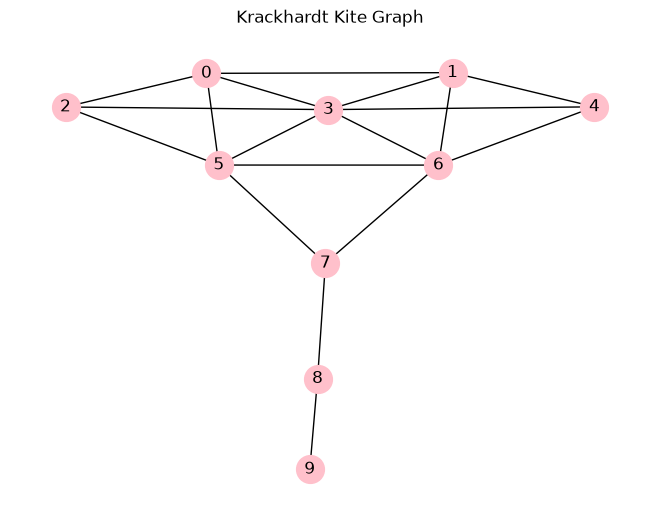

In [36]:
G = nx.krackhardt_kite_graph()

print("Nodes:", G.number_of_nodes())
print("Edges:", G.number_of_edges())

pos = nx.spring_layout(G, seed=42)

nx.draw(G, pos, with_labels=True, node_size=400, node_color="pink")

plt.title("Krackhardt Kite Graph")
plt.show()

### Reading and Writing Graphs in NetworkX

In [37]:
G = nx.Graph()
G.add_edge(1, 2, weight=4.5)
G.add_edge(2, 3, weight=2.0)

1. GraphML
One of the most popular formats because it supports:
- Node attributes
- Edge attributes
- Directed and undirected graphs

Write Graph to File
```python
nx.write_graphml(G, "graph.graphml")

In [38]:
nx.write_graphml(G, "graph.graphml")

In [39]:
G2 = nx.read_graphml("graph.graphml")

print("Nodes in G2:", G2.nodes(data=True))
print("Edges in G2:", G2.edges(data=True))

Nodes in G2: [('1', {}), ('2', {}), ('3', {})]
Edges in G2: [('1', '2', {'weight': 4.5}), ('2', '3', {'weight': 2.0})]


2. GEXF
- works well with Gephi orother visualization tools


In [40]:
# write Graph to File
nx.write_gexf(G, "graph.gexf")

In [41]:
# read Graph from File
G2 = nx.read_gexf("graph.gexf")

print("Nodes in G2:", G2.nodes(data=True))
print("Edges in G2:", G2.edges(data=True))

Nodes in G2: [('1', {'label': '1'}), ('2', {'label': '2'}), ('3', {'label': '3'})]
Edges in G2: [('1', '2', {'id': '0', 'weight': 4.5}), ('2', '3', {'id': '1', 'weight': 2.0})]


3. Edge List Format

Stores graphs as plain text edge lists. Best for: Simple graphs, Large datasets, Quick sharing



In [43]:
# Write Graph to File
nx.write_edgelist(G, "graph.edgelist")

In [44]:
G2 = nx.read_edgelist("graph.edgelist")

print("Nodes in G2:", G2.nodes(data=True))
print("Edges in G2:", G2.edges(data=True))

Nodes in G2: [('1', {}), ('2', {}), ('3', {})]
Edges in G2: [('1', '2', {'weight': 4.5}), ('2', '3', {'weight': 2.0})]


4. Adjacency List Format

Stores neighbors of each node. Best for: Sparse graphs, Compact storage



In [45]:
# Write Graph to File
nx.write_adjlist(G, "graph.adjlist")

In [46]:
# Read Graph from File
G2 = nx.read_adjlist("graph.adjlist")

print("Nodes in G2:", G2.nodes(data=True))
print("Edges in G2:", G2.edges(data=True))

Nodes in G2: [('1', {}), ('2', {}), ('3', {})]
Edges in G2: [('1', '2', {}), ('2', '3', {})]


5. Pickle Format

Stores the entire graph object exactly as-is.

    Fast save/load
    Internal Python workflows

In [47]:
# Write Graph to File
import pickle

with open("graph.pkl", "wb") as f:
    pickle.dump(G, f)

In [49]:
# Read Graph from File
with open("graph.pkl", "rb") as f:
    G_loaded = pickle.load(f)
    
print("Nodes: ", list(G_loaded.nodes(data=True)))
print("Edges: ", list(G_loaded.edges(data=True)))

Nodes:  [(1, {}), (2, {}), (3, {})]
Edges:  [(1, 2, {'weight': 4.5}), (2, 3, {'weight': 2.0})]
